# ES 335: Figures and Ridge coefficients
Makes the plots for the report and website, and reports the Ridge coefficients (direction of each effect).
Uses the same splits as notebook 01: train 2017-2020, validate 2021; final model trained 2017-2021 and tested once on 2022.
Figures are saved to `figures/`.

In [1]:
import os, re, json, warnings
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.pipeline import make_pipeline
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import Ridge
from sklearn.ensemble import HistGradientBoostingRegressor
from sklearn.inspection import permutation_importance
from sklearn.metrics import mean_squared_error, mean_absolute_error, r2_score
warnings.filterwarnings("ignore")

try:
    from google.colab import drive
    drive.mount("/content/drive")
    DATA_DIR = "/content/drive/MyDrive/es335_crop"
    FIG_DIR = "/content/drive/MyDrive/es335_figures"
except ImportError:
    DATA_DIR = os.environ.get("ES335_DATA_DIR", "es335_crop" if os.path.isdir("es335_crop") else "../es335_crop")
    FIG_DIR = "figures" if os.path.isdir("es335_crop") else "../figures"
os.makedirs(FIG_DIR, exist_ok=True)

df = pd.read_csv(f"{DATA_DIR}/corn_model_table.csv", dtype={"FIPS": str, "STATEFP": str})
weather_cols = [c for c in df.columns if re.match(r"(tavg|tmax|tmin|precip|rh|vpd|srad|heat_days)_", c)]
soil_cols    = [c for c in df.columns if c.startswith(("nitrogen", "soc", "phh2o"))]
geo_cols     = ["lat", "lon"]
full_cols    = weather_cols + geo_cols + soil_cols
ABBR = {"01":"AL","04":"AZ","05":"AR","06":"CA","08":"CO","09":"CT","10":"DE","12":"FL","13":"GA","16":"ID","17":"IL","18":"IN","19":"IA","20":"KS","21":"KY","22":"LA","23":"ME","24":"MD","25":"MA","26":"MI","27":"MN","28":"MS","29":"MO","30":"MT","31":"NE","32":"NV","33":"NH","34":"NJ","35":"NM","36":"NY","37":"NC","38":"ND","39":"OH","40":"OK","41":"OR","42":"PA","44":"RI","45":"SC","46":"SD","47":"TN","48":"TX","49":"UT","50":"VT","51":"VA","53":"WA","54":"WV","55":"WI","56":"WY"}
df["state"] = df["STATEFP"].map(ABBR)

group_of     = {**{c: "weather" for c in weather_cols}, **{c: "geo" for c in geo_cols}, **{c: "soil" for c in soil_cols}}

def scores(y, p):
    return {"RMSE": np.sqrt(mean_squared_error(y, p)), "MAE": mean_absolute_error(y, p), "R2": r2_score(y, p)}

def county_mean_baseline(train, target):
    return (target["FIPS"].map(train.groupby("FIPS")["Yield"].mean())
            .fillna(target["STATEFP"].map(train.groupby("STATEFP")["Yield"].mean()))
            .fillna(train["Yield"].mean()))

train = df[df["Year"].between(2017, 2020)]
val   = df[df["Year"] == 2021].copy()
trval = df[df["Year"].between(2017, 2021)]
test  = df[df["Year"] == 2022].copy()
plt.rcParams.update({"figure.dpi": 110, "axes.spines.top": False, "axes.spines.right": False})
print(df.shape, "| figures ->", FIG_DIR)

(8691, 63) | figures -> ../figures


## 1. Ablation: RMSE by feature set and model (2021 validation)

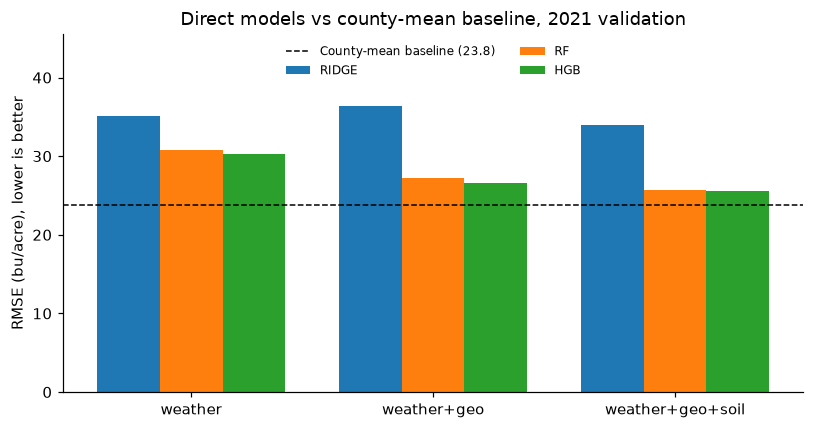

In [2]:
abl = pd.read_csv(f"{DATA_DIR}/ablation_val2021.csv")
base_rmse = scores(val["Yield"], county_mean_baseline(train, val))["RMSE"]
order = ["weather", "weather+geo", "weather+geo+soil"]
models = ["ridge", "rf", "hgb"]
fig, ax = plt.subplots(figsize=(7.5, 4))
w = 0.26
for i, m in enumerate(models):
    vals = [abl.query("features == @f and model == @m")["RMSE"].iloc[0] for f in order]
    ax.bar(np.arange(3) + (i - 1) * w, vals, w, label=m.upper())
ax.axhline(base_rmse, color="black", ls="--", lw=1, label=f"County-mean baseline ({base_rmse:.1f})")
ax.set_xticks(range(3), order); ax.set_ylabel("RMSE (bu/acre), lower is better")
ax.set_title("Direct models vs county-mean baseline, 2021 validation")
ax.set_ylim(0, max(abl["RMSE"]) * 1.25)
ax.legend(frameon=False, fontsize=8, ncol=2, loc="upper center"); plt.tight_layout()
plt.savefig(f"{FIG_DIR}/01_ablation_rmse.png", bbox_inches="tight"); plt.show()

## 2. Final model on the 2022 test year: predicted vs actual

2022 model   : {'RMSE': np.float64(24.9), 'MAE': 18.82, 'R2': 0.67}
2022 baseline: {'RMSE': np.float64(25.48), 'MAE': 18.97, 'R2': 0.65}


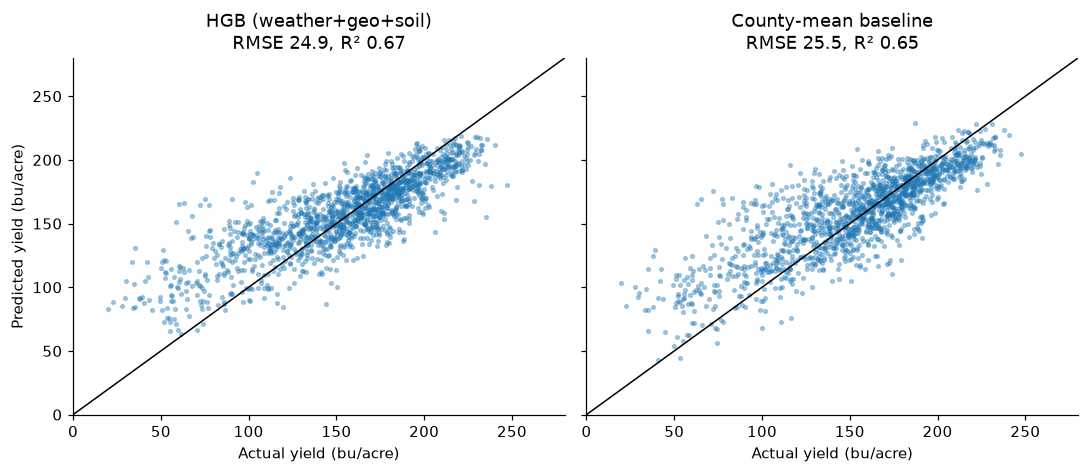

In [3]:
final = HistGradientBoostingRegressor(learning_rate=0.1, max_iter=500, min_samples_leaf=20, random_state=42)
final.fit(trval[full_cols], trval["Yield"])
test["pred"] = final.predict(test[full_cols])
test["base"] = county_mean_baseline(trval, test)
s_m, s_b = scores(test["Yield"], test["pred"]), scores(test["Yield"], test["base"])
print("2022 model   :", {k: round(v, 2) for k, v in s_m.items()})
print("2022 baseline:", {k: round(v, 2) for k, v in s_b.items()})

fig, axes = plt.subplots(1, 2, figsize=(10, 4.4), sharex=True, sharey=True)
lim = [0, 280]
for ax, col, name, s in [(axes[0], "pred", "HGB (weather+geo+soil)", s_m), (axes[1], "base", "County-mean baseline", s_b)]:
    ax.scatter(test["Yield"], test[col], s=6, alpha=0.35)
    ax.plot(lim, lim, color="black", lw=1)
    ax.set_title(f"{name}\nRMSE {s['RMSE']:.1f}, R² {s['R2']:.2f}")
    ax.set_xlabel("Actual yield (bu/acre)")
axes[0].set_ylabel("Predicted yield (bu/acre)")
axes[0].set_xlim(lim); axes[0].set_ylim(lim); plt.tight_layout()
plt.savefig(f"{FIG_DIR}/02_pred_vs_actual_2022.png", bbox_inches="tight"); plt.show()

## 3. Error by state (2022): where does the model help or hurt?

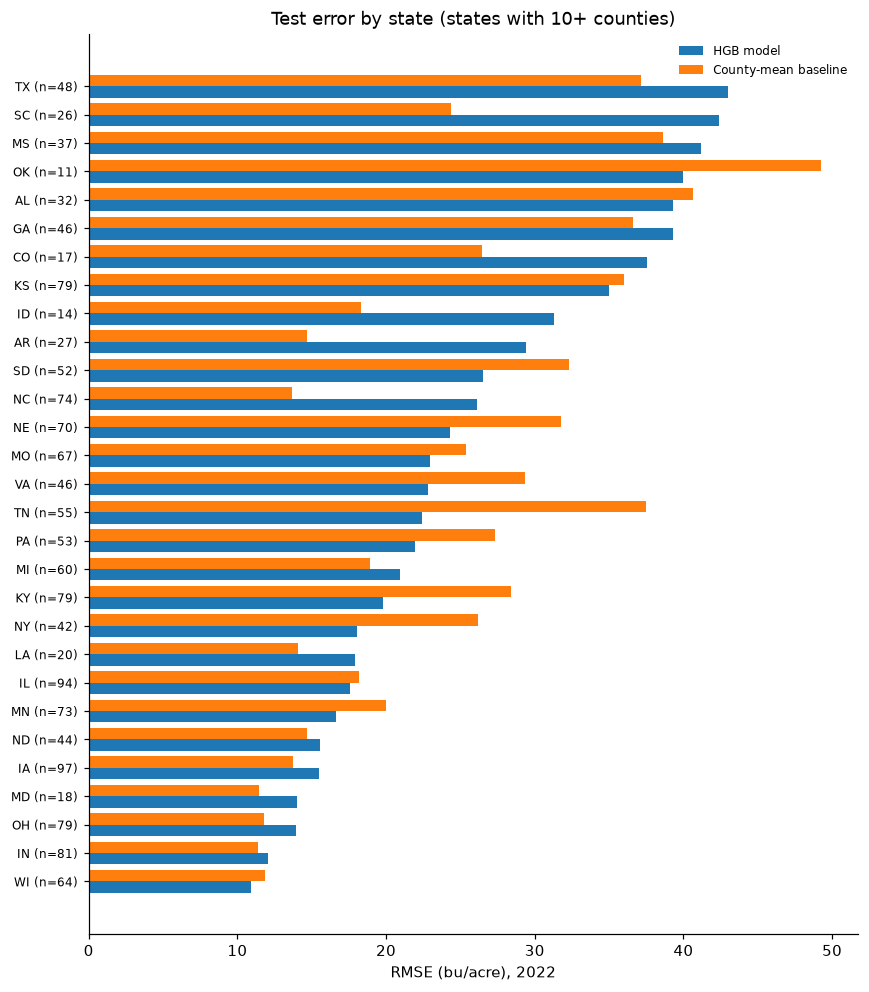

          n  model  baseline
state                       
WI     64.0   10.9      11.8
IN     81.0   12.0      11.4
OH     79.0   13.9      11.8
MD     18.0   14.0      11.4
IA     97.0   15.5      13.7
ND     44.0   15.6      14.7
MN     73.0   16.7      20.0
IL     94.0   17.5      18.2
LA     20.0   17.9      14.1
NY     42.0   18.0      26.2
KY     79.0   19.8      28.4
MI     60.0   20.9      18.9
PA     53.0   22.0      27.3
TN     55.0   22.4      37.5
VA     46.0   22.8      29.3
MO     67.0   22.9      25.3
NE     70.0   24.3      31.8
NC     74.0   26.1      13.6
SD     52.0   26.5      32.3
AR     27.0   29.4      14.7
ID     14.0   31.3      18.3
KS     79.0   35.0      36.0
CO     17.0   37.5      26.4
GA     46.0   39.3      36.6
AL     32.0   39.3      40.6
OK     11.0   40.0      49.3
MS     37.0   41.2      38.6
SC     26.0   42.4      24.4
TX     48.0   43.0      37.1


In [4]:
def rmse(g, c): return np.sqrt(((g["Yield"] - g[c]) ** 2).mean())
st = (test.groupby("state").apply(lambda g: pd.Series({"n": len(g), "model": rmse(g, "pred"), "baseline": rmse(g, "base")}))
        .query("n >= 10").sort_values("model"))
fig, ax = plt.subplots(figsize=(8, 0.28 * len(st) + 1))
y = np.arange(len(st))
ax.barh(y - 0.2, st["model"], 0.4, label="HGB model")
ax.barh(y + 0.2, st["baseline"], 0.4, label="County-mean baseline")
ax.set_yticks(y, [f"{s} (n={int(n)})" for s, n in zip(st.index, st["n"])], fontsize=8)
ax.set_xlabel("RMSE (bu/acre), 2022"); ax.set_title("Test error by state (states with 10+ counties)")
ax.legend(frameon=False, fontsize=8); plt.tight_layout()
plt.savefig(f"{FIG_DIR}/03_rmse_by_state_2022.png", bbox_inches="tight"); plt.show()
print(st.round(1).to_string())

## 4. Which features matter? Permutation importance on 2021 validation
Model trained on 2017-2020 (same as the ablation). Importance = how much validation RMSE rises when one column is shuffled.

Total importance by group (bu/acre):
group
geo         6.31
soil        5.30
weather    12.64
Name: rmse_increase, dtype: float64


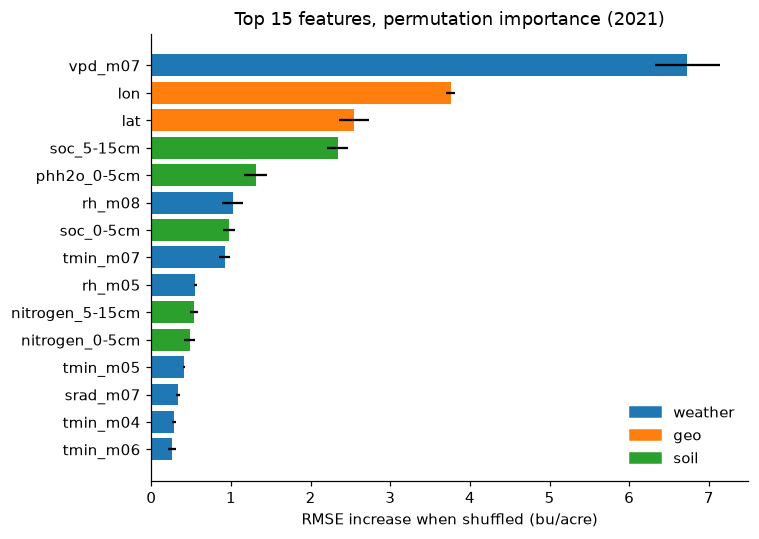

In [5]:
m_val = HistGradientBoostingRegressor(max_iter=300, learning_rate=0.05, random_state=42).fit(train[full_cols], train["Yield"])
pi = permutation_importance(m_val, val[full_cols], val["Yield"], scoring="neg_root_mean_squared_error",
                            n_repeats=5, random_state=42, n_jobs=-1)
imp = pd.DataFrame({"feature": full_cols, "rmse_increase": pi.importances_mean, "sd": pi.importances_std})
imp["group"] = imp["feature"].map(group_of)
print("Total importance by group (bu/acre):"); print(imp.groupby("group")["rmse_increase"].sum().round(2))

top = imp.sort_values("rmse_increase").tail(15)
colors = top["group"].map({"weather": "tab:blue", "geo": "tab:orange", "soil": "tab:green"})
fig, ax = plt.subplots(figsize=(7, 5))
ax.barh(top["feature"], top["rmse_increase"], xerr=top["sd"], color=colors)
from matplotlib.patches import Patch
handles = [Patch(color=c, label=g) for g, c in [("weather", "tab:blue"), ("geo", "tab:orange"), ("soil", "tab:green")]]
ax.set_xlabel("RMSE increase when shuffled (bu/acre)"); ax.set_title("Top 15 features, permutation importance (2021)")
ax.legend(handles=handles, frameon=False); plt.tight_layout()
plt.savefig(f"{FIG_DIR}/04_permutation_importance.png", bbox_inches="tight"); plt.show()

## 5. Ridge coefficients: direction of each effect
Ridge (alpha=10, standardized inputs, same pipeline as notebook 01) on weather+geo+soil, trained 2017-2020.
Because inputs are standardized, a coefficient is the change in predicted yield (bu/acre) for a one-standard-deviation increase in that feature, **holding the other features fixed**.
Monthly weather columns are strongly correlated, so individual signs can flip between neighbouring months; read them together, not one by one.
The same applies to the two soil depths: pH at 0-5 cm and 5-15 cm get large coefficients of opposite sign that largely cancel, because the two layers are almost the same number.

Ridge 2021 validation: {'RMSE': np.float64(33.94), 'MAE': 25.72, 'R2': 0.21}

Geography and soil coefficients:
        feature  coef_per_sd group
    phh2o_0-5cm        44.00  soil
   phh2o_5-15cm       -41.26  soil
     soc_5-15cm        -5.38  soil
            lon        -4.83   geo
            lat        -2.18   geo
 nitrogen_0-5cm         1.61  soil
      soc_0-5cm        -0.37  soil
nitrogen_5-15cm        -0.25  soil

Top 12 weather coefficients:
 feature  coef_per_sd   group
tavg_m07        50.97 weather
tmax_m07       -33.53 weather
tavg_m05       -31.67 weather
 vpd_m07       -30.96 weather
tavg_m08        25.63 weather
  rh_m06       -24.79 weather
tmax_m08       -23.86 weather
  rh_m07       -21.07 weather
tmin_m09       -19.75 weather
tmax_m05        18.69 weather
tmax_m09        18.49 weather
 vpd_m05        16.60 weather


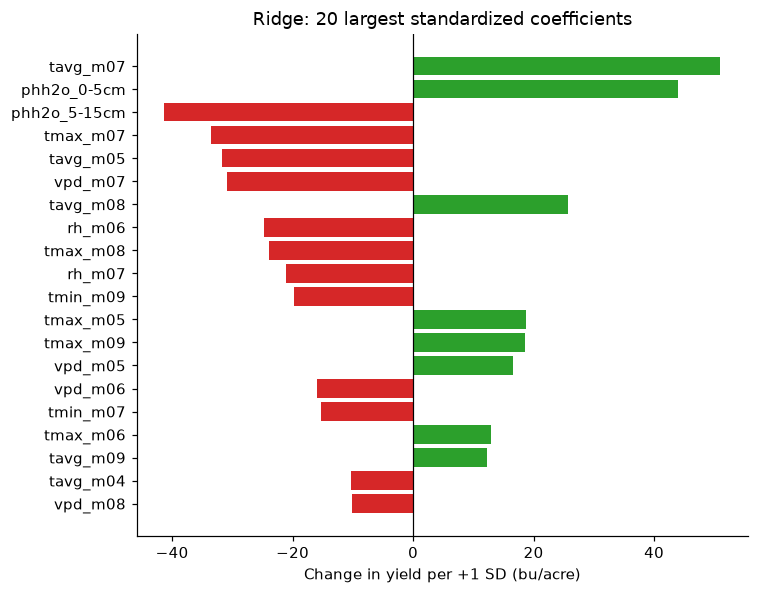

In [6]:
ridge = make_pipeline(SimpleImputer(strategy="median"), StandardScaler(), Ridge(alpha=10)).fit(train[full_cols], train["Yield"])
coef = pd.DataFrame({"feature": full_cols, "coef_per_sd": ridge[-1].coef_})
coef["group"] = coef["feature"].map(group_of)
coef = coef.reindex(coef["coef_per_sd"].abs().sort_values(ascending=False).index)
print("Ridge 2021 validation:", {k: round(v, 2) for k, v in scores(val["Yield"], ridge.predict(val[full_cols])).items()})
print("\nGeography and soil coefficients:")
print(coef[coef["group"] != "weather"].round(2).to_string(index=False))
print("\nTop 12 weather coefficients:")
print(coef[coef["group"] == "weather"].head(12).round(2).to_string(index=False))
coef.round(3).to_csv(f"{DATA_DIR}/ridge_coefficients.csv", index=False)

top = coef.head(20).iloc[::-1]
fig, ax = plt.subplots(figsize=(7, 5.5))
ax.barh(top["feature"], top["coef_per_sd"], color=np.where(top["coef_per_sd"] > 0, "tab:green", "tab:red"))
ax.axvline(0, color="black", lw=0.8)
ax.set_xlabel("Change in yield per +1 SD (bu/acre)"); ax.set_title("Ridge: 20 largest standardized coefficients")
plt.tight_layout(); plt.savefig(f"{FIG_DIR}/05_ridge_coefficients.png", bbox_inches="tight"); plt.show()

## 6. Simulator model: learned response curves
The website simulator is a Ridge on six inputs and their squares (`scripts/export_web_data.py`).
Each panel shows how its prediction changes as one input moves over its 1st-99th percentile range, with the other five at their medians.

These are associations across counties, not causal effects. For example, the soil organic carbon curve slopes down: high-carbon soils are concentrated in cooler, wetter northern counties with shorter seasons, so carbon partly stands in for location here. Read the curves as "what the model learned", not as agronomic advice.

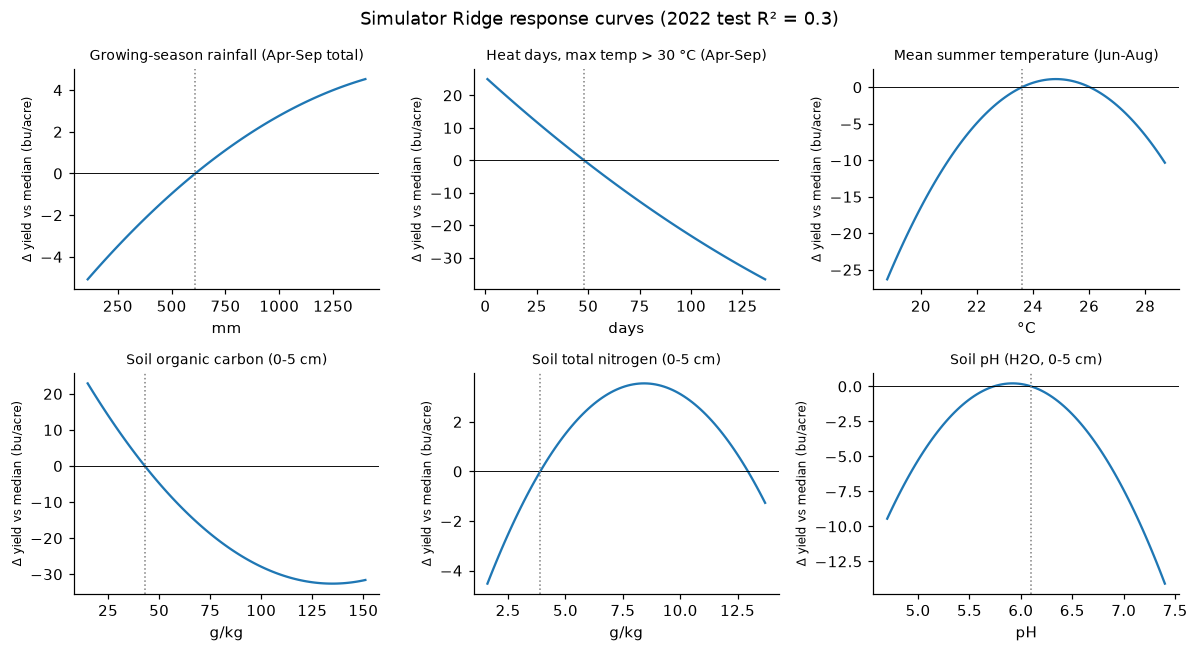

In [7]:
p = "docs/data/simulator_params.json" if os.path.exists("docs/data/simulator_params.json") else "../docs/data/simulator_params.json"
P = json.load(open(p))
fig, axes = plt.subplots(2, 3, figsize=(11, 6))
for ax, (k, f) in zip(axes.ravel(), P["features"].items()):
    x = np.linspace(f["min"], f["max"], 100)
    effect = (f["b1"] * x + f["b2"] * x ** 2) - (f["b1"] * f["default"] + f["b2"] * f["default"] ** 2)
    ax.plot(x, effect); ax.axhline(0, color="black", lw=0.6); ax.axvline(f["default"], color="grey", ls=":", lw=1)
    ax.set_title(f["name"], fontsize=9); ax.set_xlabel(f["unit"]); ax.set_ylabel("Δ yield vs median (bu/acre)", fontsize=8)
fig.suptitle(f"Simulator Ridge response curves (2022 test R² = {P['test_2022']['r2']})")
plt.tight_layout(); plt.savefig(f"{FIG_DIR}/06_simulator_response_curves.png", bbox_inches="tight"); plt.show()